**ANALYSIS OF VUL12**

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from astropy.io import fits
import os
from photutils.centroids import centroid_com, centroid_2dg  #load centroid libraries
from photutils.background import Background2D, MedianBackground
from astropy.stats import SigmaClip
from photutils.aperture import CircularAperture
from photutils.aperture import aperture_photometry, CircularAnnulus, CircularAperture
from photutils.utils import calc_total_error
from astropy.visualization import simple_norm

In [2]:
#datasets are already calibrated with master bias and master flat
#load data and seperate in filters into dictionary

dir = r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\vul12"
filters = ["black","red","green","blue"]

data = {}
for filter in filters:
    data[filter] = []

for filter in filters:
    files = os.listdir(dir + r"\\" + filter)
    for file in files:
        if "calibrated" in file:
            data[filter].append(fits.open(dir + r"\\" + filter + r"\\" + file))

#print(data)
if False:
    for filter in filters:
        l = len(data[filter]) / 3
        if l % 3 != 0:
            l = int(l) + 1 
        else:
            l=int(l)
        fig,axs = plt.subplots(l,3,figsize = (14,10))
        for i in range(len(data[filter])):
            m = int(i/3)
            n = i - 3* int(i/3)
            image = data[filter][i][0].data
            lo,up = np.percentile(image,5),np.percentile(image,99)
            axs[m][n].imshow(image,cmap='gray',clim=(lo,up),origin="lower")
        fig.suptitle("images of filter: " + filter)
        fig.tight_layout()
        plt.show()

**ALIGN AND STACK IMAGES OF EACH FILTER**

In [3]:
#image alignment and stack as single function
def align_gauss(im1,im2,pos1,pos2,plot=False, return_shift = False):
    #cut subimages from main images
    subim1 = im1[pos1[1]-30:pos1[1]+30,pos1[0]-30:pos1[0]+30]
    subim2 = im2[pos2[1]-30:pos2[1]+30,pos2[0]-30:pos2[0]+30]

    if plot == True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        lo,up = np.percentile(im1,1),np.percentile(im1,99)
        axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
        axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
        axs[0].set_title("image1")
        lo,up = np.percentile(im2,1),np.percentile(im2,99)
        axs[1].imshow(im2,cmap='gray',clim=(lo,up),origin="lower")
        axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
        axs[1].set_title("image2")
        plt.show()

    #get centers of the object
    center1,center2 = centroid_2dg(subim1)+pos1-[30,30],centroid_2dg(subim2)+pos2-[30,30] #gaussian fit
    if plot==True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        axs[0].imshow(subim1,origin="lower")
        axs[1].imshow(subim2,origin="lower")
        plt.show()

    #apply shift to second image
    im2_subshift = np.roll(im2,-int(np.round(center2[1]-center1[1])),axis=0) #shift in y
    im2_shifted = np.roll(im2_subshift,-int(np.round(center2[0]-center1[0])),axis=1) #shift in x
    im_stacked = (im1 + im2_shifted)/2 #mean in order to keep the illumination time correct

    if plot==True:
        fig, axs = plt.subplots(1,2,figsize=(10,6))
        lo,up = np.percentile(im1,1),np.percentile(im1,99)
        axs[0].imshow(im1,cmap='gray',clim=(lo,up),origin="lower")
        axs[0].hlines(y=200,xmin=0,xmax=len(im1[0])-1)
        axs[0].set_title("image1")
        lo,up = np.percentile(im2_shifted,1),np.percentile(im2_shifted,99)
        axs[1].imshow(im2_shifted,cmap='gray',clim=(lo,up),origin="lower")
        axs[1].hlines(y=200,xmin=0,xmax=len(im2[0])-1)
        axs[1].set_title("image2 shifted")
        plt.show()

        lo,up = np.percentile(im_stacked,1),np.percentile(im_stacked,99)
        plt.imshow(im_stacked,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("stacked images")
        plt.show()

    if return_shift == False:
        return im_stacked #return stacked images
    else: 
        return im2_shifted

def align_and_stack_mulitple(images,positions,plot=False):
    im1 = images[0]
    for i in range(len(images)-1):
        im2 = images[i+1]
        if plot == True:
            print(i)
        im1 = align_gauss(im1,im2,positions[0],positions[i+1],plot=plot)
    return im1

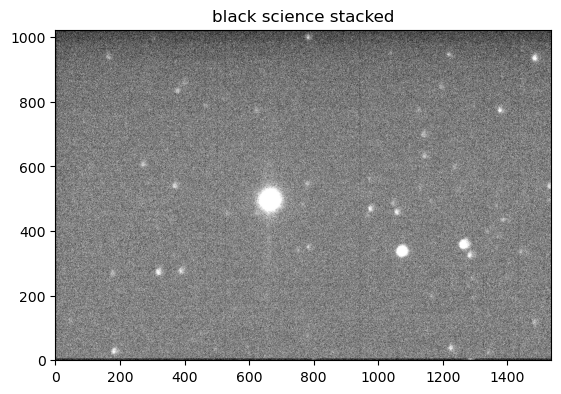

In [4]:
#black filter
filter="black"

if False:
    for i in range(10):
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[400:600,600:800],cmap='gray',clim=(lo,up),origin="lower")
        plt.grid()
        plt.show()

if True:
    off_black= (600,400) #need (x,y) for above functions
    #positions_black = [(125,130),(125,130),(125,130),(125,125),(125,125),(125,110),(125,110),(125,115),(125,115),(125,115)]
    positions_black = [(60,100) for i in range(10)]
    positions_black = [(positions_black[i][0] + off_black[0],positions_black[i][1] + off_black[1]) for i in range(len(positions_black))]

    images_black = []
    for i in range(10):
        images_black.append(data[filter][i][0].data)
        

    stacked_black = align_and_stack_mulitple(images_black,positions_black,plot=False)

#show result
if True:
        lo,up = np.percentile(stacked_black,1),np.percentile(stacked_black,99)
        plt.imshow(stacked_black,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("black science stacked")
        plt.show()


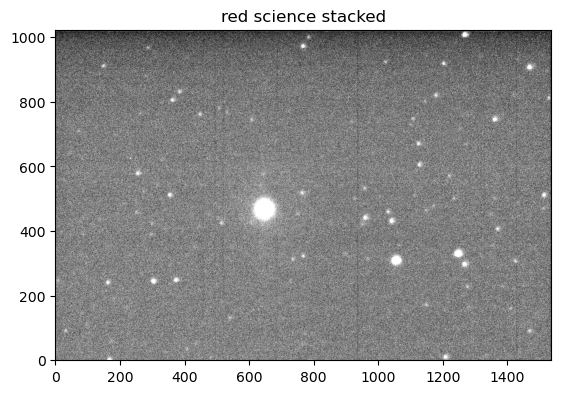

In [5]:
#red filter
filter="red"

#show images
if False:
    for i in range(10):
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[400:600:,600:800],cmap='gray',clim=(lo,up),origin="lower")
        plt.grid()
        plt.show()

#calculate stack
if True:
    off_red= (600,400) #need (x,y) for above functions
    positions_red = [(50,75) for i in range(10)]
    positions_red = [(positions_red[i][0] + off_red[0],positions_red[i][1] + off_red[1]) for i in range(len(positions_red))]

    images_red = []
    for i in range(10):
        images_red.append(data[filter][i][0].data)

    stacked_red = align_and_stack_mulitple(images_red,positions_red,plot=False)

#show result
if True:
        lo,up = np.percentile(stacked_red,1),np.percentile(stacked_red,99)
        plt.imshow(stacked_red,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("red science stacked")
        plt.show()

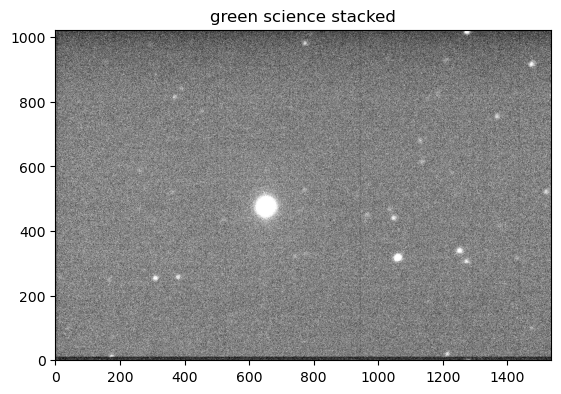

In [6]:
#green filter
filter="green"

#show images
if False:
    for i in range(10):
        print(i)
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[400:600:,600:800],cmap='gray',clim=( lo,up),origin="lower")
        plt.grid()
        plt.show()

#calculate stack
if True:
    off_green= (600,400) #need (x,y) for above functions
    positions_green = [(50,75) for i in range(10)]
    positions_green = [(positions_green[i][0] + off_green[0],positions_green[i][1] + off_green[1]) for i in range(len(positions_green))]

    images_green = []
    for i in range(10):
        images_green.append(data[filter][i][0].data)

    stacked_green = align_and_stack_mulitple(images_green,positions_green,plot=False)

#show result
if True:
        lo,up = np.percentile(stacked_green,1),np.percentile(stacked_green,99)
        plt.imshow(stacked_green,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("green science stacked")
        plt.show()

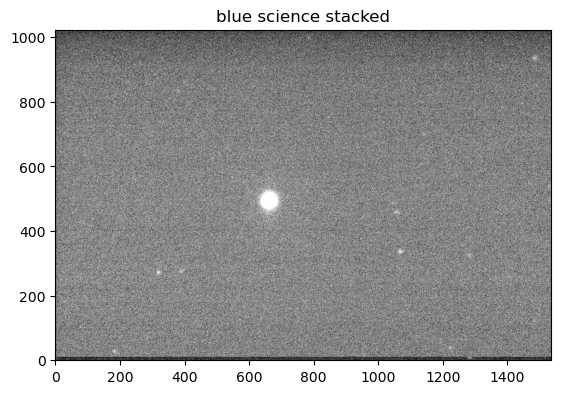

In [7]:
#blue filter
filter="blue"

#show images
if False:
    for i in range(10):
        print(i)
        lo,up = np.percentile(data[filter][i][0].data,1),np.percentile(data[filter][i][0].data,99)
        plt.imshow(data[filter][i][0].data[800:1000:,1200:1400],cmap='gray',clim=( lo,up),origin="lower")
        plt.grid()
        plt.show()

#calculate stack
if True:
    off_blue= (600,400) #need (x,y) for above functions
    positions_blue  = [(50,75) for i in range(10)]
    positions_blue = [(positions_blue[i][0] + off_blue[0],positions_blue[i][1] + off_blue[1]) for i in range(len(positions_blue))]

    images_blue = []
    for i in range(10):
        images_blue.append(data[filter][i][0].data)

    stacked_blue = align_and_stack_mulitple(images_blue,positions_blue,plot=False) 

#show result
if True:
        lo,up = np.percentile(stacked_blue,1),np.percentile(stacked_blue,99)
        plt.imshow(stacked_blue,cmap='gray',clim=(lo,up),origin="lower")
        plt.title("blue science stacked")
        plt.show()

In [8]:
#save everything in dictionary
stacked_images = {"black":stacked_black,"red":stacked_red,"green":stacked_green,"blue":stacked_blue}

**Background Subtraction**

In [9]:
#inititalize some necessary instances
sigma_clip = SigmaClip(sigma=3.0) #object used to cut out outliers out of 3sigma interval
bkg_estimator = MedianBackground() #use the median as backround estimator, could also use the mean
n = 13 #filter size

#load master flats for mask
master_flats = {}
for filter in filters:
    master_flats[filter] = fits.getdata(r"C:\Users\jw141\Desktop\astrolab_observations\data_prefiltered\\" + "master_flat_" + filter + ".fits")

#calculate the masks
masks = {}
for filter in filters:
    mask=np.zeros(np.shape(stacked_images[filter]))
    for i in range(len(stacked_images[filter])):
        for j in range(len(stacked_images[filter][i])):
            if master_flats[filter][i][j]<0.2:
                mask[i][j]=1
    mask=mask.astype(bool)
    masks[filter] = mask

#calculate backround for each filter 
bkgs = {}
for filter in filters:
    bkg = Background2D(stacked_images[filter],(50,50),filter_size=(n,n),sigma_clip=sigma_clip, bkg_estimator=bkg_estimator,coverage_mask=masks[filter])
    bkgs[filter] = bkg

#subtract background from stacked images
stacked_images_bkgcorr = {}
for filter in filters:#
    stacked_images_bkgcorr[filter] = stacked_images[filter] - bkgs[filter].background




In [10]:
#show stacked images, stacked images without backround, background and background_rms
if False:
    for filter in filters:
        fig, axs = plt.subplots(2,2,figsize=(10,6))

        lo,up = np.percentile(stacked_images[filter],1),np.percentile(stacked_images[filter],99)
        axs[0,0].imshow(stacked_images[filter],cmap='gray',clim=(lo,up),origin="lower")
        axs[0,0].set_title("stacked_images")

        lo,up = np.percentile(stacked_images_bkgcorr[filter],1),np.percentile(stacked_images_bkgcorr[filter],99)
        axs[0,1].imshow(stacked_images_bkgcorr[filter],cmap='gray',clim=(lo,up),origin="lower")
        axs[0,1].set_title("background subtracted")

        lo,up = np.percentile(bkgs[filter].background,1),np.percentile(bkgs[filter].background,99)
        axs[1,0].imshow(bkgs[filter].background,cmap='gray',clim=(lo,up),origin="lower")
        axs[1,0].set_title("background")

        lo,up = np.percentile(bkgs[filter].background_rms,1),np.percentile(bkgs[filter].background_rms,99)
        axs[1,1].imshow(bkgs[filter].background_rms,cmap='gray',clim=(lo,up),origin="lower")
        axs[1,1].set_title("background_rms")

        fig.suptitle(filter)
        plt.show()


**APERTURE PHOTOMETRY OF VUL12**

In [11]:
vul12 = stacked_images_bkgcorr

#guesses of star possions
guess = {"black":positions_black[0], "red":positions_red[0], "green" : positions_green[0], "blue" : positions_blue[0]}
print("guess: ", guess)

#get position of start for each filter
positions = {}
for filter in filters:
    #estimate star position
    img = vul12[filter][guess[filter][1]-30:guess[filter][1]+30,guess[filter][0]-30:guess[filter][0]+30]#select subportion of 60x60 image
    if False:
        plt.imshow(img,origin='lower')
        plt.show()
    position = centroid_com(img)+guess[filter]-[30,30]
    positions[filter] = (round(position[0]),round(position[1]))
print("estimate: ",positions)

#shift rgb to match with black image
vul12["red"] = align_gauss(vul12["black"],vul12["red"],positions["black"],positions["red"],plot=False, return_shift = True)
vul12["green"] = align_gauss(vul12["black"],vul12["green"],positions["black"],positions["green"],plot=False, return_shift = True)
vul12["blue"] = align_gauss(vul12["black"],vul12["blue"],positions["black"],positions["blue"],plot=False, return_shift = True)

position = positions["black"] #position of vul12 in all filter images



guess:  {'black': (660, 500), 'red': (650, 475), 'green': (650, 475), 'blue': (650, 475)}
estimate:  {'black': (663, 494), 'red': (646, 466), 'green': (652, 474), 'blue': (662, 493)}


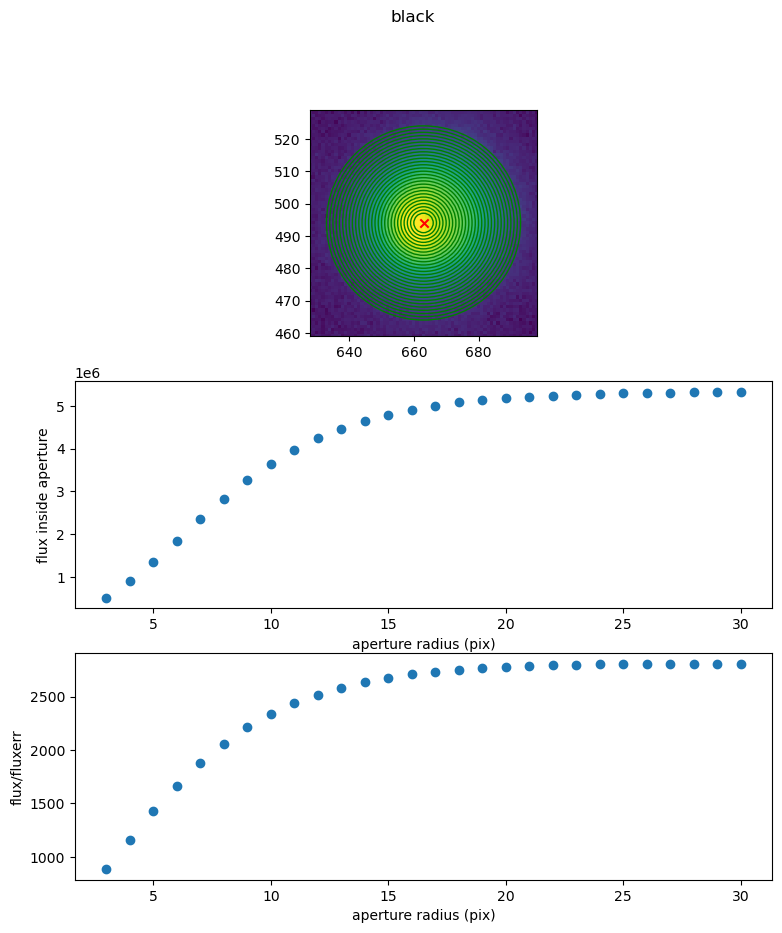

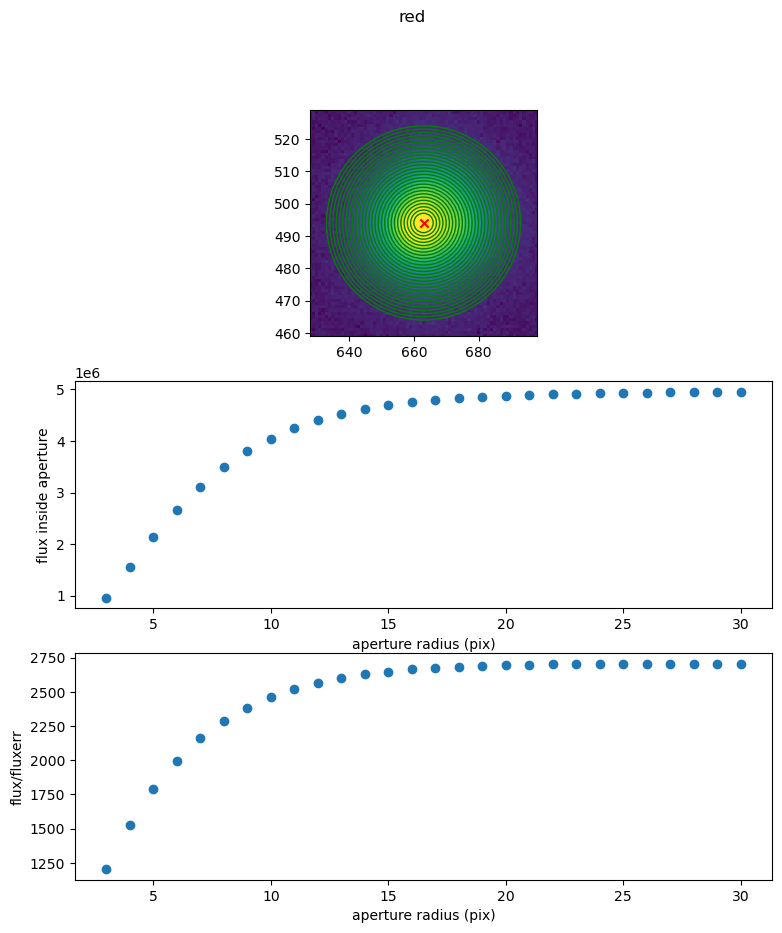

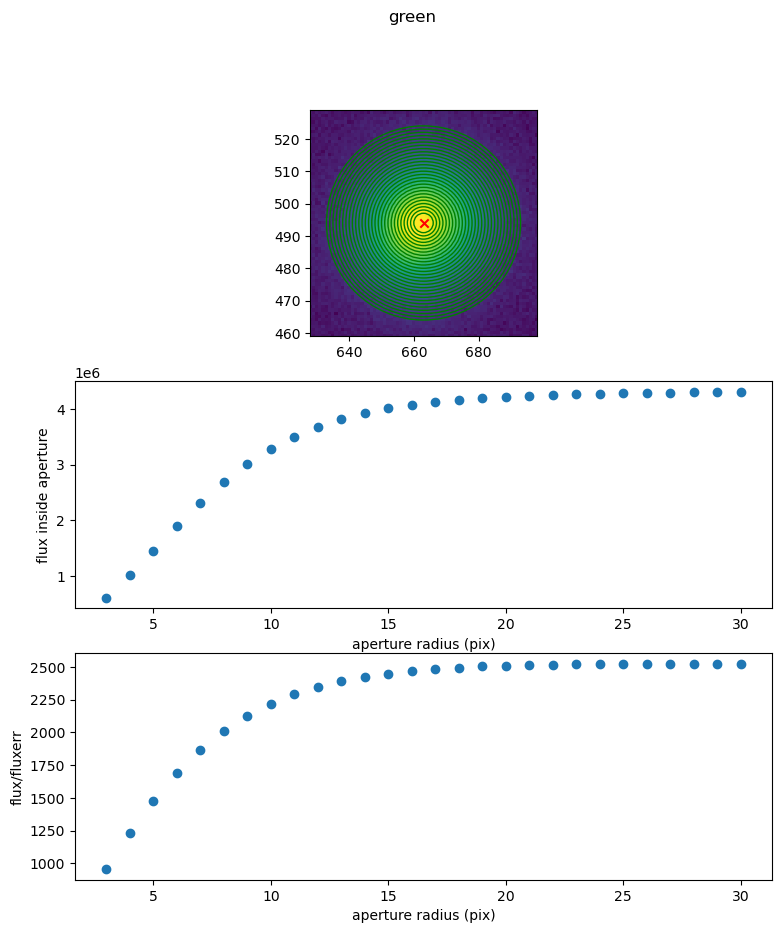

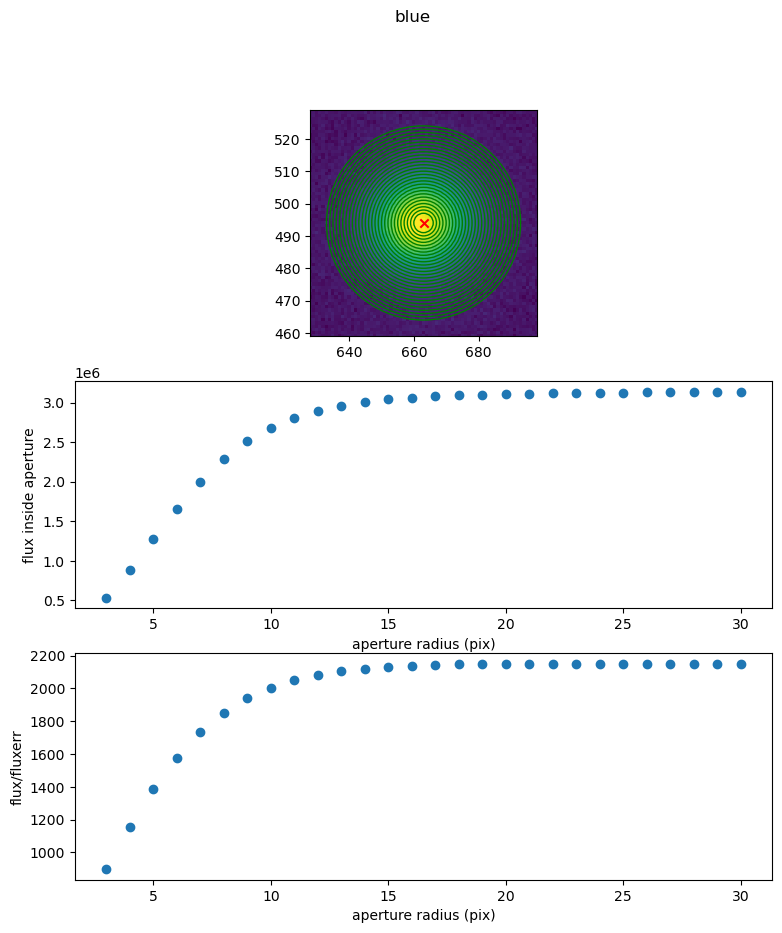

In [12]:
#PERFORM PHOTOMETRY OF VUL12

radii = np.arange(3,31)  # radii (pix) of circular apertures
aperture = [CircularAperture(position, r=r) for r in radii] # define circular apertures

ys = {}
erys = {}
for filter in filters:
    erimage = calc_total_error(vul12[filter], bkgs[filter].background_rms, 1.5) 
    phot_table = aperture_photometry(vul12[filter], aperture,error=erimage)
    y = np.asarray([phot_table['aperture_sum_'+str(i)] for i in np.arange(0,radii.size)],dtype=float)
    ery = np.asarray([phot_table['aperture_sum_err_'+str(i)] for i in np.arange(0,radii.size)],dtype=float)
    y=np.reshape(y, (len(y),))
    ery=np.reshape(ery, (len(ery),))
    ys[filter] = y
    erys[filter] = ery

    fig,ax = plt.subplots(3,figsize=(9,10))
    fig.suptitle(filter)
    norm = simple_norm(img,'log',percent=99.)
    ax[0].imshow(vul12[filter],norm=norm,cmap='viridis', aspect=1, interpolation='nearest')
    ax[0].scatter(position[0],position[1],color='red',marker='x')
    for r in radii:
        circle = plt.Circle(position,r,color='green',fill=False)
        ax[0].add_artist(circle)
    ax[0].set_xlim([position[0]-35,position[0]+35])
    ax[0].set_ylim([position[1]-35,position[1]+35])
    # plot curve of growth
    ax[1].errorbar(radii,y,yerr=ery,fmt='o')
    ax[1].set_xlabel('aperture radius (pix)')
    ax[1].set_ylabel('flux inside aperture')
    # plot flux/fluxerr (S/N)
    ax[2].errorbar(radii,y/ery,fmt='o')
    ax[2].set_xlabel('aperture radius (pix)')
    ax[2].set_ylabel('flux/fluxerr')



In [13]:
radius = 20
#calculate flux for each filter in given radius

exptime = {}
for filter in filters:
    exptime[filter] = data[filter][0][0].header["exptime"]



fluxs = {}
flux_errors = {}
for filter in filters:
    flux = ys[filter][np.round(radii) == np.round(radius)]
    error = erys[filter][np.round(radii) == np.round(radius)]
    fluxs[filter] = flux
    flux_errors[filter] = error
    print(" Star flux (counts): %f +/- %f" %(flux,error))
    print(" Star flux/time (counts/s): %f +/- %f" %(flux/exptime[filter],error/exptime[filter]))


 Star flux (counts): 5178793.750434 +/- 1863.091771
 Star flux/time (counts/s): 5178793.750434 +/- 1863.091771
 Star flux (counts): 4873931.274418 +/- 1808.075776
 Star flux/time (counts/s): 1624643.758139 +/- 602.691925
 Star flux (counts): 4222521.334492 +/- 1683.424780
 Star flux/time (counts/s): 1407507.111497 +/- 561.141593
 Star flux (counts): 3108303.775973 +/- 1445.536936
 Star flux/time (counts/s): 1036101.258658 +/- 481.845645


C:\Users\jw141\AppData\Local\Temp\ipykernel_18444\1116895826.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(" Star flux (counts): %f +/- %f" %(flux,error))
C:\Users\jw141\AppData\Local\Temp\ipykernel_18444\1116895826.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print(" Star flux/time (counts/s): %f +/- %f" %(flux/exptime[filter],error/exptime[filter]))


In [18]:
#instrumental magnitude:
m_inst = {}
for filter in filters:
    m_inst[filter] = -2.5* np.log10(fluxs[filter]/exptime[filter])

print("m without airmass correction",m_inst)

#account for airmass
airmass = 1.2 
extinction = {"red":0.09, "green":0.15, "blue":0.25}
m_inst_0 = {}
for filter in ["red","green","blue"]:
    m_inst_0[filter] = m_inst[filter] - extinction[filter]*airmass 

print("m with airmass correction",m_inst_0)

#literature catalogue of magnitude from SIMBAD
m_real = {"red":4.98, "green":4.96, "blue":4.84}  #here: green=V

#calculate zeropoint for each filter - account for airmass
ZP = {}
for filter in ["red","green","blue"]:
    ZP[filter] = m_real[filter] - m_inst_0[filter]
    print("ZP " + filter + ": ", ZP[filter])

m without airmass correction {'black': array([-16.78557154]), 'red': array([-15.52689537]), 'green': array([-15.37112649]), 'blue': array([-15.0385055])}
m with airmass correction {'red': array([-15.63489537]), 'green': array([-15.55112649]), 'blue': array([-15.3385055])}
ZP red:  [20.61489537]
ZP green:  [20.51112649]
ZP blue:  [20.1785055]


In [21]:
#convert zeropoints to fluxes
flux_ZP = {}
for filter in ["red","green","blue"]:
    flux_ZP[filter] = 10**(ZP[filter]/-2.5)
    print("flux ZP " + filter + ": ", flux_ZP[filter])

max_flux = max(flux_ZP.values())
for filter in flux_ZP.keys():
    flux_ZP[filter] = flux_ZP[filter]/max_flux
    print("normalized flux ZP " + filter + ": ", flux_ZP[filter])

flux ZP red:  [5.67599303e-09]
flux ZP green:  [6.24524388e-09]
flux ZP blue:  [8.48394411e-09]
normalized flux ZP red:  [0.66902763]
normalized flux ZP green:  [0.73612506]
normalized flux ZP blue:  [1.]
